In [5]:
%pip install xgboost

Defaulting to user installation because normal site-packages is not writeable
You should consider upgrading via the '/Library/Developer/CommandLineTools/usr/bin/python3 -m pip install --upgrade pip' command.
Note: you may need to restart the kernel to use updated packages.


In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from xgboost import XGBRegressor

# This Loads the modeling dataset
df = pd.read_csv("real_personal_income_growth/data/modeling_data.csv")
df["Date"] = pd.to_datetime(df["Date"])

# Adds a 2-year rolling average so the model can see the recent trend without losing rows
df["rolling_mean_2"] = df["income_growth"].rolling(window=2, min_periods=1).mean()
predictors = ["income_growth", "rolling_mean_2"]

# This will Split the data 80% training and 20% testing
split_index = int(len(df) * 0.8)
train_df = df.iloc[:split_index].copy()
test_df = df.iloc[split_index:].copy()

X_train = train_df[predictors].values
y_train = train_df["actual_future"].values
X_test = test_df[predictors].values
y_test = test_df["actual_future"].values

# Regularized the XGBoost settings to stop it from overfitting our small dataset
xgb_model = XGBRegressor(
    n_estimators=25,
    max_depth=1,
    learning_rate=0.05,
    min_child_weight=3,
    subsample=0.8,
    reg_alpha=1.0,
    reg_lambda=5.0,
    random_state=42
)
xgb_model.fit(X_train, y_train)

# Generates the predictions on the test set
xgb_pred = xgb_model.predict(X_test)

# Evaluates the model using MAE, RMSE, and R^2
errors = y_test - xgb_pred
mae = np.abs(errors).mean()
rmse = np.sqrt((errors ** 2).mean())

ss_res = (errors ** 2).sum()
ss_tot = ((y_test - y_test.mean()) ** 2).sum()
r2 = 1 - (ss_res / ss_tot)

print("--- Tuned XGBoost Evaluation (Test Set) ---")
print(f"Mean Absolute Error (MAE): {mae:.2f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.2f}")
print(f"R^2: {r2:.2f}\n")

# Saves the updated predictions to the results folder
test_df["xgboost_prediction"] = xgb_pred
test_df[["Date", "actual_future", "xgboost_prediction"]].to_csv(
    "real_personal_income_growth/results/xgboost_predictions.csv", index=False
)

# Generates predictions across the full timeline for plotting
df["xgboost_prediction"] = xgb_model.predict(df[predictors].values)


--- Tuned XGBoost Evaluation (Test Set) ---
Mean Absolute Error (MAE): 1.34
Root Mean Squared Error (RMSE): 1.35
R^2: -0.76



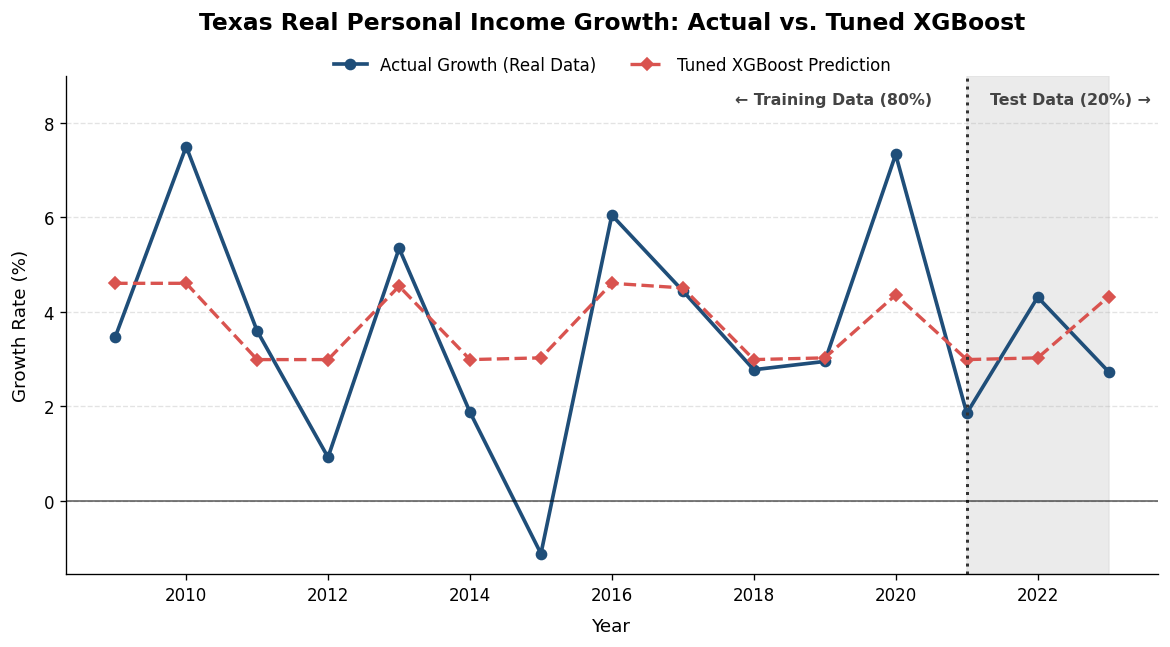

In [7]:
# Used AI to make the graph look cleaner, label the train/test split, and fix text spacing
plt.figure(figsize=(10, 5.5), dpi=120)
ax = plt.gca()

# Plots actual vs tuned XGBoost predictions
plt.plot(
    df["Date"], df["actual_future"],
    marker="o", markersize=6, linewidth=2.2,
    color="#1f4e79", label="Actual Growth (Real Data)"
)
plt.plot(
    df["Date"], df["xgboost_prediction"],
    marker="D", markersize=5.5, linewidth=2, linestyle="--",
    color="#d9534f", label="Tuned XGBoost Prediction"
)

# Highlights the 20% testing period
split_date = test_df["Date"].iloc[0]
plt.axvline(split_date, color="#333333", linestyle=":", linewidth=1.8)
plt.axvspan(split_date, df["Date"].iloc[-1], color="#dcdcdc", alpha=0.55)

# Adds extra space at the top so the split labels don't touch the 2020 peak
y_max = max(df["actual_future"].max(), df["xgboost_prediction"].max())
plt.ylim(top=y_max + 1.5)
y_top = ax.get_ylim()[1]

plt.text(split_date - pd.Timedelta(days=180), y_top - 0.35, "← Training Data (80%)",
         ha="right", va="top", fontsize=9.5, fontweight="bold", color="#444444")
plt.text(split_date + pd.Timedelta(days=120), y_top - 0.35, "Test Data (20%) →",
         ha="left", va="top", fontsize=9.5, fontweight="bold", color="#444444")

# Adds a horizontal line at 0% growth
plt.axhline(0, color="black", linewidth=1, alpha=0.6)

# Cleans up borders and gridlines
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.grid(axis="y", linestyle="--", alpha=0.35)

# Title, labels, and legend
plt.title("Texas Real Personal Income Growth: Actual vs. Tuned XGBoost", fontsize=14, fontweight="bold", pad=28)
plt.xlabel("Year", fontsize=11, labelpad=8)
plt.ylabel("Growth Rate (%)", fontsize=11, labelpad=8)
plt.legend(loc="upper center", bbox_to_anchor=(0.5, 1.07), ncol=2, frameon=False, fontsize=10)

plt.tight_layout()
plt.savefig("real_personal_income_growth/figures/xgboost_actual_vs_predicted.png", dpi=300, bbox_inches="tight")
plt.show()
